# LAB 12 — Artificial Neural Networks: The Perceptron
## Student Information
- **Name: Ritika Lund**
- **Roll No: 023-24-0262**
- **Section: H**
- **Date: 17-11-2026**

**Dataset:** Iris (sklearn built-in) · Use `random_state=42` everywhere · Write a 1–2 sentence interpretation under every plot and table.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, make_classification
from sklearn.linear_model import Perceptron, LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

np.random.seed(42)
iris = load_iris()
print("Iris loaded:", iris.data.shape, "| Classes:", iris.target_names)

Iris loaded: (150, 4) | Classes: ['setosa' 'versicolor' 'virginica']


## Part 1 — The Neuron From Scratch

### Task 1.1 — Weighted sum, step function and predict
Write `weighted_sum`, `step_function`, `predict`. Verify slide 16 (`predict([0.6,0.8],[2,3],-2)` → 1) and slide 17 (w=[1,−0.5], b=0.5; inputs [1,1],[2,1],[0,3] → 1, 1, 0).

In [4]:
# Task 1.1

def weighted_sum(w, x, b):
    return np.dot(w, x) + b


def step_function(z):
    return 1 if z >= 0 else 0


def predict(w, x, b):
    z = weighted_sum(w, x, b)
    return step_function(z)
# Slide 16 verification
result = predict([0.6, 0.8], [2, 3], -2)

print("Prediction:", result)
# Slide 17 verification
w = [1, -0.5]
b = 0.5

inputs = [[1, 1], [2, 1], [0, 3]]

for x in inputs:
    print(f"Input: {x}, Prediction: {predict(w, x, b)}")

Prediction: 1
Input: [1, 1], Prediction: 1
Input: [2, 1], Prediction: 1
Input: [0, 3], Prediction: 0


### Task 1.2 — One full epoch on the AND gate, by hand
AND: (0,0,0), (0,1,0), (1,0,0), (1,1,1). Start w=[0.2, −0.1], b=0, η=0.1. Print z, ŷ, e and the new w, b for each row; then the mistake count and "Converged!" / "Keep training.".

In [5]:
# Task 1.2


X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

y = np.array([0, 0, 0, 1])

# Initial parameters
w = np.array([0.2, -0.1], dtype=float)
b = 0.0
eta = 0.1

mistakes = 0


for x, actual in zip(X, y):

    # Calculate weighted sum
    z = weighted_sum(w, x, b)

    # Make prediction
    y_hat = step_function(z)


    e = actual - y_hat

    print("Input:", x)
    print("Actual:", actual)
    print("Weighted sum:", round(z, 2))
    print("Prediction:", y_hat)
    print("Error:", e)

    if e != 0:
        w = w + eta * e * x
        b = b + eta * e
        mistakes += 1

    print("Updated weights:", w)
    print("Updated bias:", round(b, 2))
    print("-" * 35)

print("Final weights:", w)
print("Final bias:", b)
print("Total mistakes:", mistakes)

if mistakes == 0:
    print("Converged!")
else:
    print("Keep training.")


Input: [0 0]
Actual: 0
Weighted sum: 0.0
Prediction: 1
Error: -1
Updated weights: [ 0.2 -0.1]
Updated bias: -0.1
-----------------------------------
Input: [0 1]
Actual: 0
Weighted sum: -0.2
Prediction: 0
Error: 0
Updated weights: [ 0.2 -0.1]
Updated bias: -0.1
-----------------------------------
Input: [1 0]
Actual: 0
Weighted sum: 0.1
Prediction: 1
Error: -1
Updated weights: [ 0.1 -0.1]
Updated bias: -0.2
-----------------------------------
Input: [1 1]
Actual: 1
Weighted sum: -0.2
Prediction: 0
Error: 1
Updated weights: [0.2 0. ]
Updated bias: -0.1
-----------------------------------
Final weights: [0.2 0. ]
Final bias: -0.1
Total mistakes: 3
Keep training.


## Part 2 — Train a Perceptron From Scratch

### Task 2.1 — Implement `train_perceptron`
`train_perceptron(X, y, eta=0.1, max_epochs=100)`: start from zeros, update on every mistake, record mistakes per epoch, stop after a zero-mistake epoch. Train on OR (y = [0,1,1,1]) and print w, b.

In [7]:
# Task 2.1

def train_perceptron(X, y, eta=0.1, max_epochs=100):


    w = np.zeros(X.shape[1])
    b = 0.0


    mistakes = []

    for epoch in range(max_epochs):

        epoch_mistakes = 0

       
        for x, actual in zip(X, y):

            # Calculate prediction
            y_hat = predict(w, x, b)

            # Calculate error
            e = actual - y_hat

            # Update if prediction is wrong
            if e != 0:
                w = w + eta * e * x
                b = b + eta * e
                epoch_mistakes += 1

       
        mistakes.append(epoch_mistakes)

        print(f"Epoch {epoch + 1}: Mistakes = {epoch_mistakes}")

        # Stop if no mistakes remain
        if epoch_mistakes == 0:
            break

    return w, b, mistakes
# OR gate dataset
X_or = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

y_or = np.array([0, 1, 1, 1])

# Train perceptron
w_or, b_or, mistakes_or = train_perceptron(
    X_or, y_or, eta=0.1, max_epochs=100
)

print("\nFinal weights:", w_or)
print("Final bias:", b_or)
print("Mistakes per epoch:", mistakes_or)

Epoch 1: Mistakes = 2
Epoch 2: Mistakes = 2
Epoch 3: Mistakes = 1
Epoch 4: Mistakes = 0

Final weights: [0.1 0.1]
Final bias: -0.1
Mistakes per epoch: [2, 2, 1, 0]


### Task 2.2 — Plot mistakes per epoch
Title "Perceptron training on OR gate", axes "Epoch" / "Mistakes"; mark the final epoch with a red dot.

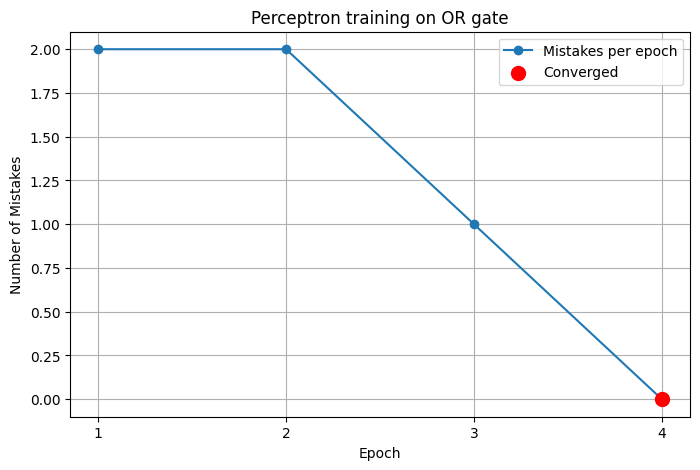

In [8]:
# Task 2.2

epochs = range(1, len(mistakes_or) + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    mistakes_or,
    marker='o',
    label='Mistakes per epoch'
)


plt.scatter(
    epochs[-1],
    mistakes_or[-1],
    color='red',
    s=100,
    label='Converged',
    zorder=5
)

plt.title("Perceptron training on OR gate")
plt.xlabel("Epoch")
plt.ylabel("Number of Mistakes")
plt.xticks(list(epochs))
plt.grid(True)
plt.legend()

plt.show()


**Interpretation:** *The number of mistakes decreased from 2 to 0 over four epochs. The perceptron successfully learned the OR gate and converged in the fourth epoch.*

## Part 3 — The Decision Boundary

### Task 3.1 — Plot the OR gate with its boundary
Boundary: x₂ = −(w₁/w₂)x₁ − b/w₂ over `np.linspace(-0.5, 1.5, 100)`. Class 0 blue circles, class 1 red squares, boundary black dashed. Write a reusable `plot_boundary(ax, w, b)` that handles w₂ = 0.

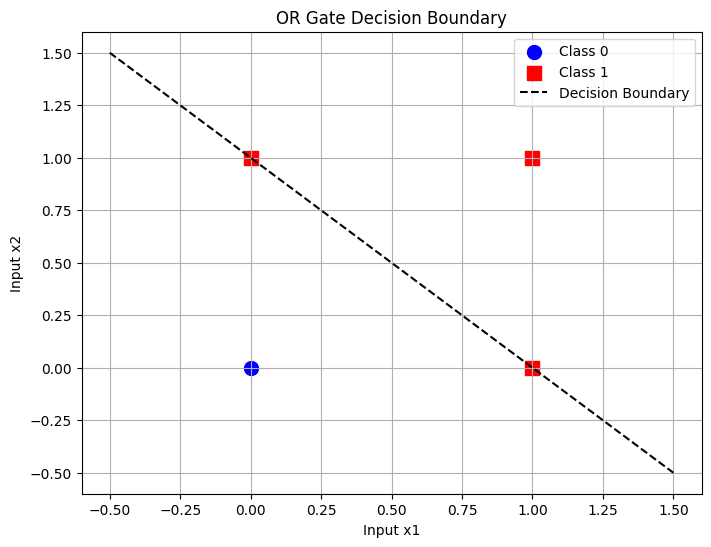

In [9]:
# Task 3.1

def plot_boundary(ax, w, b):

    x1 = np.linspace(-0.5, 1.5, 100)

    if w[1] != 0:
        x2 = -(w[0] / w[1]) * x1 - b / w[1]
        ax.plot(x1, x2, 'k--', label='Decision Boundary')

    else:
        x1_boundary = -b / w[0]
        ax.axvline(
            x=x1_boundary,
            color='black',
            linestyle='--',
            label='Decision Boundary'
        )


class_0 = X_or[y_or == 0]
class_1 = X_or[y_or == 1]

fig, ax = plt.subplots(figsize=(8, 6))


ax.scatter(
    class_0[:, 0],
    class_0[:, 1],
    color='blue',
    marker='o',
    s=100,
    label='Class 0'
)


ax.scatter(
    class_1[:, 0],
    class_1[:, 1],
    color='red',
    marker='s',
    s=100,
    label='Class 1'
)


plot_boundary(ax, w_or, b_or)

ax.set_title("OR Gate Decision Boundary")
ax.set_xlabel("Input x1")
ax.set_ylabel("Input x2")
ax.legend()
ax.grid(True)

plt.show()


**Interpretation:** *The decision boundary is a straight line represented by x₂ = 1 − x₁. The perceptron predicts class 1 for points on or above the line and class 0 for points below it.*

### Task 3.2 — With and without bias
Train both versions on X=[[1,0],[0,1],[2,1],[1,2]], y=[0,0,1,1]; plot the two boundaries side by side. Did the no-bias version converge?

Epoch 1: Mistakes = 2
Epoch 2: Mistakes = 3
Epoch 3: Mistakes = 1
Epoch 4: Mistakes = 0
WITH BIAS
Weights: [0.1 0.1]
Bias: -0.2
Mistakes: [2, 3, 1, 0]

WITHOUT BIAS
Weights: [0.1 0. ]
Bias: 0.0
Mistakes: [3, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2, 3, 3, 2]


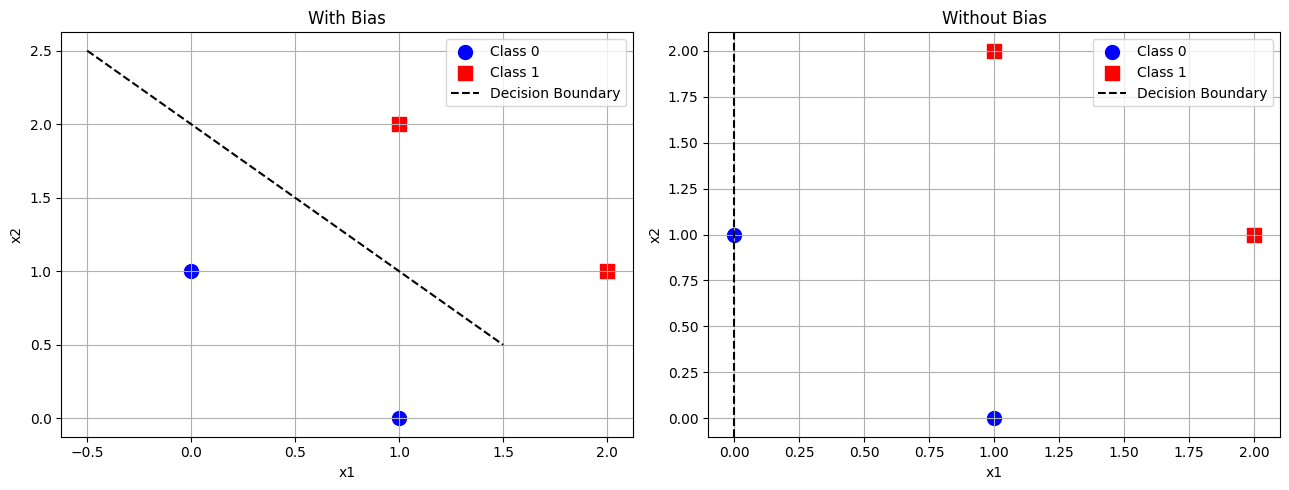

In [10]:
# Task 3.2

def train_perceptron_no_bias(X, y, eta=0.1, max_epochs=100):

    # Initialize weights
    w = np.zeros(X.shape[1])

    # Bias is fixed at zero
    b = 0.0

    mistakes = []

    for epoch in range(max_epochs):

        epoch_mistakes = 0

        for x, actual in zip(X, y):

            # Prediction without bias updates
            y_hat = predict(w, x, b)

            e = actual - y_hat

            if e != 0:
                # Update weights only
                w = w + eta * e * x
                epoch_mistakes += 1

        mistakes.append(epoch_mistakes)

        if epoch_mistakes == 0:
            break

    return w, b, mistakes
# Dataset from the lab manual
X_bias = np.array([
    [1, 0],
    [0, 1],
    [2, 1],
    [1, 2]
])

y_bias = np.array([0, 0, 1, 1])

# Train with bias
w_with, b_with, mistakes_with = train_perceptron(
    X_bias, y_bias
)

# Train without bias
w_without, b_without, mistakes_without = train_perceptron_no_bias(
    X_bias, y_bias
)

print("WITH BIAS")
print("Weights:", w_with)
print("Bias:", b_with)
print("Mistakes:", mistakes_with)

print("\nWITHOUT BIAS")
print("Weights:", w_without)
print("Bias:", b_without)
print("Mistakes:", mistakes_without)
fig = plt.figure(figsize=(13, 5))

# Plot with bias
ax1 = plt.subplot(1, 2, 1)

ax1.scatter(
    X_bias[y_bias == 0, 0],
    X_bias[y_bias == 0, 1],
    color='blue',
    marker='o',
    s=100,
    label='Class 0'
)

ax1.scatter(
    X_bias[y_bias == 1, 0],
    X_bias[y_bias == 1, 1],
    color='red',
    marker='s',
    s=100,
    label='Class 1'
)

plot_boundary(ax1, w_with, b_with)

ax1.set_title("With Bias")
ax1.set_xlabel("x1")
ax1.set_ylabel("x2")
ax1.legend()
ax1.grid(True)



ax2 = plt.subplot(1, 2, 2)

ax2.scatter(
    X_bias[y_bias == 0, 0],
    X_bias[y_bias == 0, 1],
    color='blue',
    marker='o',
    s=100,
    label='Class 0'
)

ax2.scatter(
    X_bias[y_bias == 1, 0],
    X_bias[y_bias == 1, 1],
    color='red',
    marker='s',
    s=100,
    label='Class 1'
)

plot_boundary(ax2, w_without, b_without)

ax2.set_title("Without Bias")
ax2.set_xlabel("x1")
ax2.set_ylabel("x2")
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

**Interpretation:** *The perceptron with bias converged successfully, while the perceptron without bias did not converge within 100 epochs. Removing bias forces the decision boundary to pass through the origin, limiting the model's ability to separate the classes.*

## Part 4 — The XOR Limitation

### Task 4.1 — Watch the perceptron fail
XOR: y = [0,1,1,0], `max_epochs=100`. Print final mistakes, w, b; plot mistakes per epoch and the boundary.

Epoch 1: Mistakes = 3
Epoch 2: Mistakes = 3
Epoch 3: Mistakes = 4
Epoch 4: Mistakes = 4
Epoch 5: Mistakes = 4
Epoch 6: Mistakes = 4
Epoch 7: Mistakes = 4
Epoch 8: Mistakes = 4
Epoch 9: Mistakes = 4
Epoch 10: Mistakes = 4
Epoch 11: Mistakes = 4
Epoch 12: Mistakes = 4
Epoch 13: Mistakes = 4
Epoch 14: Mistakes = 4
Epoch 15: Mistakes = 4
Epoch 16: Mistakes = 4
Epoch 17: Mistakes = 4
Epoch 18: Mistakes = 4
Epoch 19: Mistakes = 4
Epoch 20: Mistakes = 4
Epoch 21: Mistakes = 4
Epoch 22: Mistakes = 4
Epoch 23: Mistakes = 4
Epoch 24: Mistakes = 4
Epoch 25: Mistakes = 4
Epoch 26: Mistakes = 4
Epoch 27: Mistakes = 4
Epoch 28: Mistakes = 4
Epoch 29: Mistakes = 4
Epoch 30: Mistakes = 4
Epoch 31: Mistakes = 4
Epoch 32: Mistakes = 4
Epoch 33: Mistakes = 4
Epoch 34: Mistakes = 4
Epoch 35: Mistakes = 4
Epoch 36: Mistakes = 4
Epoch 37: Mistakes = 4
Epoch 38: Mistakes = 4
Epoch 39: Mistakes = 4
Epoch 40: Mistakes = 4
Epoch 41: Mistakes = 4
Epoch 42: Mistakes = 4
Epoch 43: Mistakes = 4
Epoch 44: Mistakes =

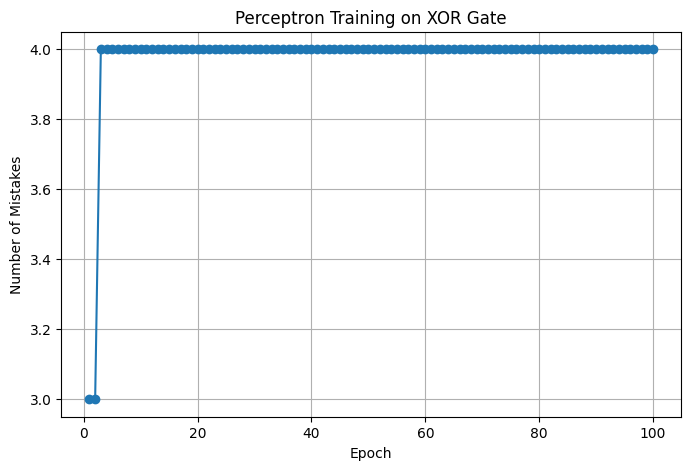

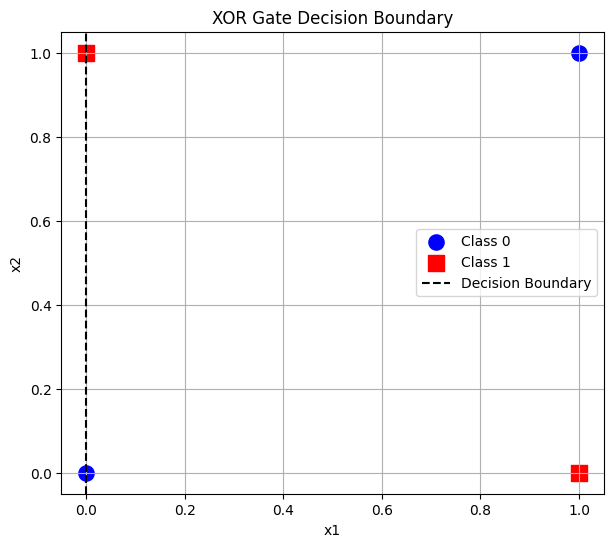

In [12]:
# Task 4.1

# XOR dataset
X_xor = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

y_xor = np.array([0, 1, 1, 0])

# Train perceptron
w_xor, b_xor, mistakes_xor = train_perceptron(
    X_xor,
    y_xor,
    eta=0.1,
    max_epochs=100
)

# Print final results
print("\nFinal results:")
print("Final mistakes:", mistakes_xor[-1])
print("Final weights:", w_xor)
print("Final bias:", b_xor)
print("Total epochs:", len(mistakes_xor))
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(mistakes_xor) + 1),
    mistakes_xor,
    marker='o'
)

plt.title("Perceptron Training on XOR Gate")
plt.xlabel("Epoch")
plt.ylabel("Number of Mistakes")
plt.grid(True)

plt.show()
fig, ax = plt.subplots(figsize=(7, 6))

# Class 0
ax.scatter(
    X_xor[y_xor == 0, 0],
    X_xor[y_xor == 0, 1],
    color='blue',
    marker='o',
    s=120,
    label='Class 0'
)

# Class 1
ax.scatter(
    X_xor[y_xor == 1, 0],
    X_xor[y_xor == 1, 1],
    color='red',
    marker='s',
    s=120,
    label='Class 1'
)

# Final decision boundary
plot_boundary(ax, w_xor, b_xor)

ax.set_title("XOR Gate Decision Boundary")
ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.legend()
ax.grid(True)

plt.show()

**Interpretation:** *The perceptron does not reach zero mistakes even after 100 epochs. XOR is not linearly separable, so a single perceptron cannot correctly classify all four input combinations using one straight decision boundary.*

### Task 4.2 — Confirm no weight vector works
`check_xor(w, b)` returns True only if all four XOR constraints hold. Test 10,000 random (w₁, w₂, b) in [−5, 5].

In [13]:
# Task 4.2

def check_xor(w, b):

    condition_1 = np.dot(w, [0, 0]) + b < 0
    condition_2 = np.dot(w, [0, 1]) + b >= 0
    condition_3 = np.dot(w, [1, 0]) + b >= 0
    condition_4 = np.dot(w, [1, 1]) + b < 0

    return (
        condition_1 and
        condition_2 and
        condition_3 and
        condition_4
    )

# Generate random weights and biases
np.random.seed(42)

random_weights = np.random.uniform(-5, 5, (10000, 2))
random_biases = np.random.uniform(-5, 5, 10000)

# Count successful combinations
count = 0
first_solution = None

for w, b in zip(random_weights, random_biases):

    if check_xor(w, b):
        count += 1

        if first_solution is None:
            first_solution = (w, b)

# Display results
print("Total combinations tested:", 10000)
print("Valid solutions found:", count)

if count == 0:
    print("No solution found")
else:
    print("First solution:", first_solution)


Total combinations tested: 10000
Valid solutions found: 0
No solution found


## Part 5 — scikit-learn Perceptron on Iris

### Task 5.1 — Train and evaluate
Petal features (2, 3), Setosa vs rest; 70/30 stratified split; `Perceptron(random_state=42)`. Print accuracy, confusion matrix, report, `coef_`, `intercept_`.

In [14]:
# Task 5.1

# Load Iris dataset
iris = load_iris()

# Select petal length and petal width
X = iris.data[:, (2, 3)]

# Binary target: Setosa = 1, Rest = 0
y = (iris.target == 0).astype(int)

# Check dataset
print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("Unique classes:", np.unique(y))
print("First 5 feature rows:\n", X[:5])
print("First 5 targets:", y[:5])
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
# Create the model
clf = Perceptron(random_state=42)

# Train the model
clf.fit(X_train, y_train)

# Predict test data
y_pred = clf.predict(X_test)
# Accuracy
accuracy = accuracy_score(y_test, y_pred)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Classification report
report = classification_report(y_test, y_pred)

print("Accuracy:", accuracy)

print("\nConfusion Matrix:")
print(cm)

print("\nClassification Report:")
print(report)
print("Learned weights (coef_):")
print(clf.coef_)

print("\nLearned bias (intercept_):")
print(clf.intercept_)

Feature shape: (150, 2)
Target shape: (150,)
Unique classes: [0 1]
First 5 feature rows:
 [[1.4 0.2]
 [1.4 0.2]
 [1.3 0.2]
 [1.5 0.2]
 [1.4 0.2]]
First 5 targets: [1 1 1 1 1]
Training samples: 105
Testing samples: 45
Accuracy: 1.0

Confusion Matrix:
[[30  0]
 [ 0 15]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        30
           1       1.00      1.00      1.00        15

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45

Learned weights (coef_):
[[-1.3 -2.2]]

Learned bias (intercept_):
[4.]


**Interpretation:** *The coef_ attribute represents the learned weights of the perceptron, while intercept_ represents its bias. These correspond to w and b that we implemented manually in Part 1.*

### Task 5.2 — Visualise the learned boundary
Boundary from `coef_[0]`, `intercept_[0]`; test set coloured by class; misclassified points as red ×.

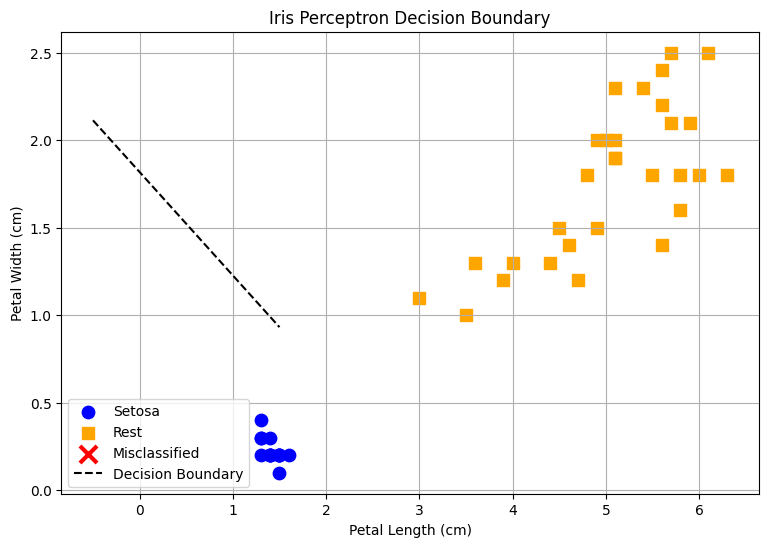

Misclassified points: 0


In [15]:
# Task 5.2

fig, ax = plt.subplots(figsize=(9, 6))

# Separate test samples by class
setosa = y_test == 1
rest = y_test == 0

# Plot Setosa
ax.scatter(
    X_test[setosa, 0],
    X_test[setosa, 1],
    color='blue',
    marker='o',
    s=80,
    label='Setosa'
)

# Plot other Iris species
ax.scatter(
    X_test[rest, 0],
    X_test[rest, 1],
    color='orange',
    marker='s',
    s=80,
    label='Rest'
)

# Identify misclassified points
misclassified = y_test != y_pred

# Plot misclassified points LAST
ax.scatter(
    X_test[misclassified, 0],
    X_test[misclassified, 1],
    color='red',
    marker='x',
    s=150,
    linewidths=3,
    label='Misclassified'
)

# Draw learned decision boundary
plot_boundary(ax, clf.coef_[0], clf.intercept_[0])

ax.set_title("Iris Perceptron Decision Boundary")
ax.set_xlabel("Petal Length (cm)")
ax.set_ylabel("Petal Width (cm)")
ax.legend()
ax.grid(True)

plt.show()

# Count misclassified points
print("Misclassified points:", np.sum(misclassified))


**Interpretation:** *The model misclassified 0 out of 45 test samples, achieving 100% accuracy. The decision boundary is a straight line because the perceptron is a linear classifier.*

### Task 5.3 — Effect of learning rate
`eta0` = 0.001, 0.1, 10.0. Table of eta0 | accuracy | `n_iter_` | `coef_`. Do the predictions change? What does η do when training starts from w = 0?

In [16]:
# Task 5.3

learning_rates = [0.001, 0.1, 10.0]

results = []

for eta in learning_rates:

    # Create model with selected learning rate
    model = Perceptron(
        eta0=eta,
        random_state=42
    )

    # Train model
    model.fit(X_train, y_train)

    # Predict
    predictions = model.predict(X_test)

    # Calculate accuracy
    accuracy = accuracy_score(y_test, predictions)

    # Store results
    results.append({
        "eta0": eta,
        "accuracy": accuracy,
        "n_iter": model.n_iter_,
        "coef": model.coef_[0].copy()
        
    })

# Print comparison table
print(f"{'eta0':<12}{'Accuracy':<12}{'n_iter':<12}{'coef_'}")

for result in results:
    print(
        f"{result['eta0']:<12}"
        f"{result['accuracy']:<12.4f}"
        f"{result['n_iter']:<12}"
        f"{result['coef']}"
    )


eta0        Accuracy    n_iter      coef_
0.001       1.0000      6           [-0.0013 -0.0022]
0.1         1.0000      7           [-0.13 -0.22]
10.0        1.0000      7           [-13. -22.]


**Interpretation:** *All three learning rates achieved 100% test accuracy. However, the learned weights and number of iterations differed. A larger learning rate produced larger weight values, but it did not improve accuracy. This shows that learning rate affects the training process and learned parameters.*

## Part 6 — Multi-Class Classification

### Task 6.1 — All three Iris classes
All four features, `y = iris.target`, 70/30 stratified; `Perceptron(random_state=42, max_iter=1000)`. Print report, confusion matrix, `coef_.shape`. Which class is hardest?

In [17]:
# Task 6.1

# Use all four Iris features
X_multi = iris.data

# Use all three original classes
y_multi = iris.target

# Split into training and testing data
X_train_multi, X_test_multi, y_train_multi, y_test_multi = train_test_split(
    X_multi,
    y_multi,
    test_size=0.3,
    random_state=42,
    stratify=y_multi
)

print("Feature shape:", X_multi.shape)
print("Target shape:", y_multi.shape)
print("Training samples:", X_train_multi.shape[0])
print("Testing samples:", X_test_multi.shape[0])
print("Classes:", iris.target_names)

# Create multi-class perceptron
clf_multi = Perceptron(
    random_state=42,
    max_iter=1000
)

# Train model
clf_multi.fit(X_train_multi, y_train_multi)

# Predict test data
y_pred_multi = clf_multi.predict(X_test_multi)

print("Multi-class model trained successfully!")

# Classification report
print("Classification Report:")
print(
    classification_report(
        y_test_multi,
        y_pred_multi,
        target_names=iris.target_names
    )
)

# Confusion matrix
cm_multi = confusion_matrix(y_test_multi, y_pred_multi)

print("\nConfusion Matrix:")
print(cm_multi)

# Accuracy
print("\nAccuracy:", accuracy_score(y_test_multi, y_pred_multi))
print("Shape of coefficient matrix:", clf_multi.coef_.shape)

print("\nLearned coefficients:")
print(clf_multi.coef_)

Feature shape: (150, 4)
Target shape: (150,)
Training samples: 105
Testing samples: 45
Classes: ['setosa' 'versicolor' 'virginica']
Multi-class model trained successfully!
Classification Report:
              precision    recall  f1-score   support

      setosa       0.52      1.00      0.68        15
  versicolor       0.00      0.00      0.00        15
   virginica       0.94      1.00      0.97        15

    accuracy                           0.67        45
   macro avg       0.48      0.67      0.55        45
weighted avg       0.48      0.67      0.55        45


Confusion Matrix:
[[15  0  0]
 [14  0  1]
 [ 0  0 15]]

Accuracy: 0.6666666666666666
Shape of coefficient matrix: (3, 4)

Learned coefficients:
[[  2.1   7.3  -9.9  -4.5]
 [  4.5 -29.1   6.7 -14.7]
 [-35.5 -25.1  46.2  45.7]]


C:\Users\TECHNEZO\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\TECHNEZO\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\TECHNEZO\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _war

**Interpretation:** *Each row of clf_multi.coef_ represents the learned weights associated with one class, while each column corresponds to one input feature. The model uses these coefficients to distinguish between the three Iris species.*

### Task 6.2 — Perceptron vs Logistic Regression
`LogisticRegression(random_state=42, max_iter=200)` on the same split; side-by-side accuracy and macro-F1; why can it win (slide 32)?

In [20]:
# Task 6.2



# Create Logistic Regression model
log_model = LogisticRegression(
    random_state=42,
    max_iter=200
)


log_model.fit(X_train_multi, y_train_multi)

# Predictions
y_pred_log = log_model.predict(X_test_multi)

print("Logistic Regression trained successfully!")


per_accuracy = accuracy_score(
    y_test_multi, y_pred_multi
)

per_f1 = f1_score(
    y_test_multi, y_pred_multi,
    average='macro'
)


log_accuracy = accuracy_score(
    y_test_multi, y_pred_log
)

log_f1 = f1_score(
    y_test_multi, y_pred_log,
    average='macro'
)


print(f"{'Model':<25}{'Accuracy':<15}{'Macro-F1'}")
print("-" * 55)

print(
    f"{'Perceptron':<25}"
    f"{per_accuracy:<15.4f}"
    f"{per_f1:.4f}"
)

print(
    f"{'Logistic Regression':<25}"
    f"{log_accuracy:<15.4f}"
    f"{log_f1:.4f}"
)


Logistic Regression trained successfully!
Model                    Accuracy       Macro-F1
-------------------------------------------------------
Perceptron               0.6667         0.5499
Logistic Regression      0.9333         0.9333


**Interpretation:** *Logistic Regression performed better than the Perceptron, achieving 93.33% accuracy and 0.9333 Macro-F1 compared to 66.67% accuracy and 0.5499 Macro-F1. Logistic Regression uses probability-based predictions and optimizes a smooth loss function, which helps it learn more effectively for this dataset*

## Part 7 — Graded Questions (5 marks)
Answer in the Markdown cells below, using your own numbers.

**Q1 [0.5 marks] — Manual update trace.** w = [0.5, −0.3], b = 0.2, η = 0.1, x = [1, 2], y = 0. Compute z and ŷ, then e, then the updated w₁, w₂ and b.

*The weighted sum is 0.1, so the predicted output is 1. Since the actual output is 0, the error is -1. After applying the perceptron learning rule, the updated weights become [0.4, -0.5] and the updated bias becomes 0.1.*

**Q2 [0.5 marks] — Boundary geometry.** After training on AND: w = [0.3, 0.2], b = −0.4. Write the boundary equation. Which side is (1, 1) on, and what is ŷ?

*The decision boundary is represented by the equation 0.3x1 + 0.2x2 - 0.4 = 0. For the point (1,1), the weighted sum is 0.1, which is positive. Therefore, the point lies above the decision boundary and is classified as class 1.*

**Q3 [1 mark] — XOR analysis.** (a) Show algebraically that the four XOR constraints cannot all hold. (b) Sketch XOR on x₁–x₂ axes (insert an image or a matplotlib plot) to show why no line separates it. (c) Name one architectural change that solves XOR.

*a)The four XOR conditions are b < 0, w₂ + b ≥ 0, w₁ + b ≥ 0, and w₁ + w₂ + b < 0. Adding the middle two conditions and comparing with the fourth gives b > 0, which contradicts b < 0. Therefore, no combination of weights and bias can correctly classify XOR using a single perceptron.*

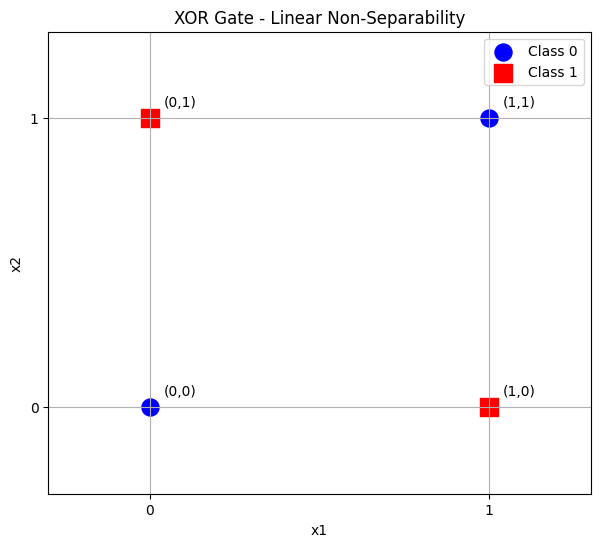

In [22]:
# b)
X_xor = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

y_xor = np.array([0, 1, 1, 0])
plt.figure(figsize=(7, 6))

# Class 0
plt.scatter(
    X_xor[y_xor == 0, 0],
    X_xor[y_xor == 0, 1],
    color='blue',
    marker='o',
    s=150,
    label='Class 0'
)

# Class 1
plt.scatter(
    X_xor[y_xor == 1, 0],
    X_xor[y_xor == 1, 1],
    color='red',
    marker='s',
    s=150,
    label='Class 1'
)

# Label each point
for x, y in X_xor:
    plt.text(x + 0.04, y + 0.04, f'({x},{y})')

plt.title("XOR Gate - Linear Non-Separability")
plt.xlabel("x1")
plt.ylabel("x2")

plt.xticks([0, 1])
plt.yticks([0, 1])

plt.xlim(-0.3, 1.3)
plt.ylim(-0.3, 1.3)

plt.grid(True)
plt.legend()
plt.show()

*The XOR dataset contains two classes arranged diagonally opposite to each other. Class 0 contains (0,0) and (1,1), while Class 1 contains (0,1) and (1,0). No single straight line can separate these classes, which demonstrates that XOR is not linearly separable.*



*c) A Multilayer Perceptron (MLP) with at least one hidden layer and a nonlinear activation function, such as ReLU or sigmoid, can solve the XOR problem. The hidden layer allows the network to learn nonlinear decision boundaries, which a single-layer perceptron cannot represent.*

**Q4 [1.5 marks] — Iris extension.** Add sepal length (feature 0) so you use features (0, 2, 3). Retrain the Part 5 model; report accuracy and macro-F1. Does the extra feature help? Support your answer with numbers.

In [27]:
# Q4
X_extended = iris.data[:, (0, 2, 3)]

# Keep the same binary target
y_extended = (iris.target == 0).astype(int)

print("Feature shape:", X_extended.shape)
print("Target shape:", y_extended.shape)
print("Selected features:", iris.feature_names[0:1] +
      iris.feature_names[2:4])

X_train_ext, X_test_ext, y_train_ext, y_test_ext = train_test_split(
    X_extended,
    y_extended,
    test_size=0.3,
    random_state=42,
    stratify=y_extended
)

print("Training samples:", X_train_ext.shape[0])
print("Testing samples:", X_test_ext.shape[0])


clf_extended = Perceptron(random_state=42)

clf_extended.fit(X_train_ext, y_train_ext)

y_pred_ext = clf_extended.predict(X_test_ext)

print("Extended Perceptron trained successfully!")

# Calculate accuracy
accuracy_ext = accuracy_score(y_test_ext, y_pred_ext)

# Calculate Macro-F1
f1_ext = f1_score(
    y_test_ext,
    y_pred_ext,
    average='macro'
)

print("Extended Model Accuracy:", accuracy_ext)
print("Extended Model Macro-F1:", f1_ext)

print(f"{'Model':<30}{'Accuracy':<15}{'Macro-F1'}")
print("-" * 60)

print(
    f"{'Original (2 features)':<30}"
    f"{accuracy_score(y_test, y_pred):<15.4f}"
    f"{f1_score(y_test, y_pred, average='macro'):.4f}"
)

print(
    f"{'Extended (3 features)':<30}"
    f"{accuracy_ext:<15.4f}"
    f"{f1_ext:.4f}"
)


Feature shape: (150, 3)
Target shape: (150,)
Selected features: ['sepal length (cm)', 'petal length (cm)', 'petal width (cm)']
Training samples: 105
Testing samples: 45
Extended Perceptron trained successfully!
Extended Model Accuracy: 1.0
Extended Model Macro-F1: 1.0
Model                         Accuracy       Macro-F1
------------------------------------------------------------
Original (2 features)         1.0000         1.0000
Extended (3 features)         1.0000         1.0000


*The original model using two features (Petal Length and Petal Width) achieved 100% accuracy and 1.0000 Macro-F1. After adding Sepal Length as a third feature, the model still achieved 100% accuracy and 1.0000 Macro-F1. Therefore, the extra feature did not improve the model's performance because the original two features were already sufficient to classify Setosa from the other Iris species correctly.*

**Q5 [1.5 marks] — Synthetic data.** `make_classification(n_samples=200, n_features=2, n_redundant=0, n_clusters_per_class=1, random_state=42)`, 70/30 split. Train your hand-built perceptron and sklearn's. Compare accuracy, epochs, final w and b; plot both boundaries side by side.

Feature shape: (200, 2)
Target shape: (200,)
Unique classes: [0 1]

First 5 feature rows:
 [[-0.87292898  0.013042  ]
 [ 1.31293463  2.77053357]
 [ 2.34042818  2.42099601]
 [ 2.29454774 -0.40438019]
 [ 0.94410516  0.4772409 ]]
First 5 targets: [1 1 1 1 1]
Training samples: 140
Testing samples: 60
Epoch 1: Mistakes = 33
Epoch 2: Mistakes = 30
Epoch 3: Mistakes = 33
Epoch 4: Mistakes = 32
Epoch 5: Mistakes = 29
Epoch 6: Mistakes = 29
Epoch 7: Mistakes = 35
Epoch 8: Mistakes = 29
Epoch 9: Mistakes = 31
Epoch 10: Mistakes = 31
Epoch 11: Mistakes = 33
Epoch 12: Mistakes = 31
Epoch 13: Mistakes = 35
Epoch 14: Mistakes = 34
Epoch 15: Mistakes = 36
Epoch 16: Mistakes = 33
Epoch 17: Mistakes = 33
Epoch 18: Mistakes = 33
Epoch 19: Mistakes = 30
Epoch 20: Mistakes = 32
Epoch 21: Mistakes = 32
Epoch 22: Mistakes = 36
Epoch 23: Mistakes = 37
Epoch 24: Mistakes = 31
Epoch 25: Mistakes = 33
Epoch 26: Mistakes = 36
Epoch 27: Mistakes = 30
Epoch 28: Mistakes = 32
Epoch 29: Mistakes = 34
Epoch 30: Mista

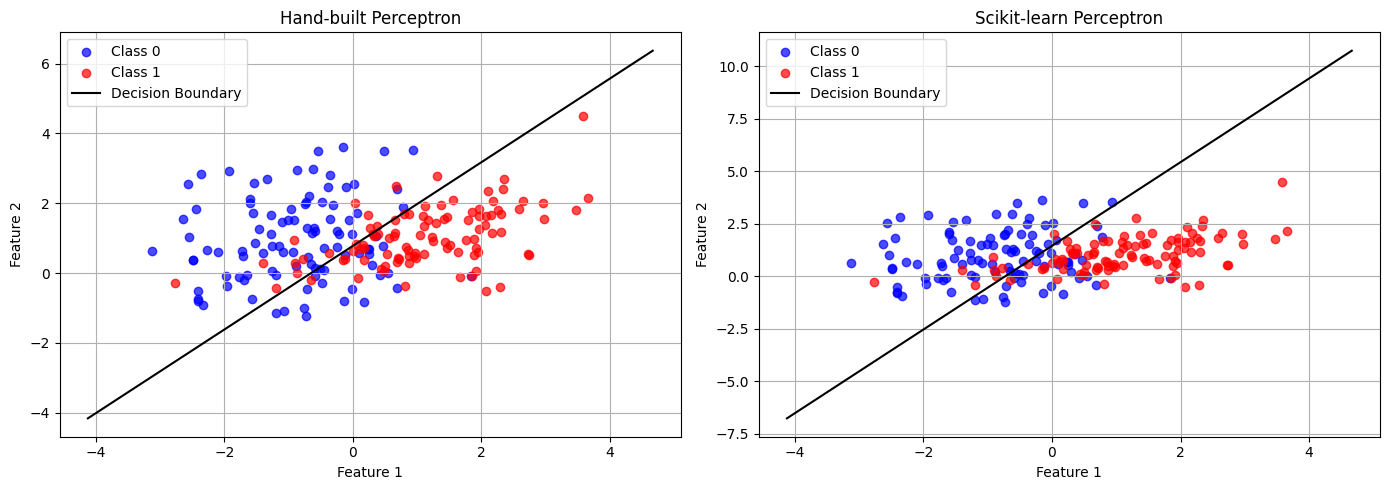

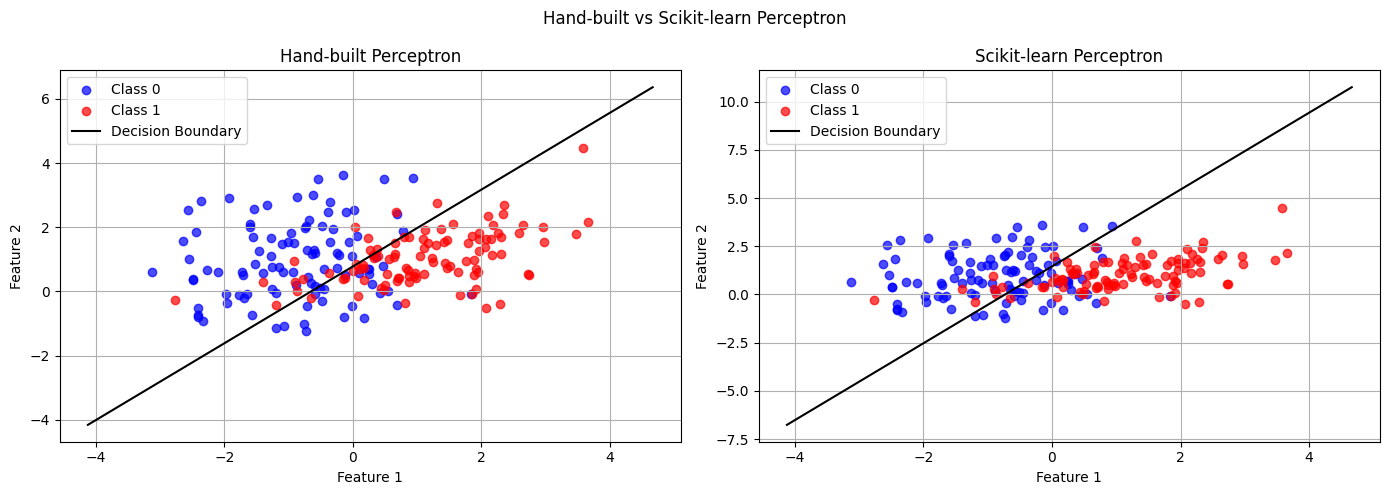

In [35]:
# Q5

X_syn, y_syn = make_classification(
    n_samples=200,
    n_features=2,
    n_redundant=0,
    n_clusters_per_class=1,
    random_state=42
)

# Check dataset
print("Feature shape:", X_syn.shape)
print("Target shape:", y_syn.shape)
print("Unique classes:", np.unique(y_syn))
print("\nFirst 5 feature rows:\n", X_syn[:5])
print("First 5 targets:", y_syn[:5])

X_train_syn, X_test_syn, y_train_syn, y_test_syn = train_test_split(
    X_syn,
    y_syn,
    test_size=0.3,
    random_state=42
)

print("Training samples:", X_train_syn.shape[0])
print("Testing samples:", X_test_syn.shape[0])
# Train our hand-built Perceptron
w_syn, b_syn, mistakes_syn = train_perceptron(
    X_train_syn,
    y_train_syn,
    eta=0.1,
    max_epochs=100
)

print("\nHand-built Perceptron Results")
print("Final weights:", w_syn)
print("Final bias:", b_syn)
print("Total epochs:", len(mistakes_syn))
print("Final mistakes:", mistakes_syn[-1])
from sklearn.linear_model import Perceptron

sk_model = Perceptron(
    eta0=0.1,
    max_iter=100,
    tol=None,
    random_state=42,
    shuffle=False
)


sk_model.fit(X_train_syn, y_train_syn)


y_pred_sk = sk_model.predict(X_test_syn)

print("Scikit-learn Perceptron Results")
print("Weights:", sk_model.coef_[0])
print("Bias:", sk_model.intercept_[0])
print("Epochs:", sk_model.n_iter_)
print("Converged:", sk_model.n_iter_ < 100)


y_pred_manual = (
    np.dot(X_test_syn, w_syn) + b_syn >= 0
).astype(int)


manual_accuracy = accuracy_score(
    y_test_syn, y_pred_manual
)

sklearn_accuracy = accuracy_score(
    y_test_syn, y_pred_sk
)

print("Hand-built Perceptron Accuracy:", manual_accuracy)
print("Scikit-learn Perceptron Accuracy:", sklearn_accuracy)

print(f"{'Metric':<25}{'Hand-built':<18}{'Scikit-learn'}")
print("-" * 60)

print(
    f"{'Accuracy':<25}"
    f"{manual_accuracy:<18.4f}"
    f"{sklearn_accuracy:.4f}"
)

print(
    f"{'Epochs':<25}"
    f"{len(mistakes_syn):<18}"
    f"{sk_model.n_iter_}"
)

print("\nHand-built weights:", w_syn)
print("Scikit-learn weights:", sk_model.coef_[0])

print("\nHand-built bias:", b_syn)
print("Scikit-learn bias:", sk_model.intercept_[0])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

models = [
    (w_syn, b_syn, "Hand-built Perceptron"),
    (sk_model.coef_[0], sk_model.intercept_[0],
     "Scikit-learn Perceptron")
]

for ax, (weights, bias, title) in zip(axes, models):

    # Plot class 0
    ax.scatter(
        X_syn[y_syn == 0, 0],
        X_syn[y_syn == 0, 1],
        color='blue',
        label='Class 0',
        alpha=0.7
    )

    # Plot class 1
    ax.scatter(
        X_syn[y_syn == 1, 0],
        X_syn[y_syn == 1, 1],
        color='red',
        label='Class 1',
        alpha=0.7
    )

    # Decision boundary: w1*x1 + w2*x2 + b = 0
    x_values = np.linspace(
        X_syn[:, 0].min() - 1,
        X_syn[:, 0].max() + 1,
        100
    )

    if abs(weights[1]) > 1e-10:
        y_values = (
            -weights[0] * x_values - bias
        ) / weights[1]

        ax.plot(
            x_values,
            y_values,
            color='black',
            label='Decision Boundary'
        )

    ax.set_title(title)
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

models = [
    (w_syn, b_syn, "Hand-built Perceptron"),
    (sk_model.coef_[0], sk_model.intercept_[0],
     "Scikit-learn Perceptron")
]

for ax, (weights, bias, title) in zip(axes, models):

    # Plot class 0
    ax.scatter(
        X_syn[y_syn == 0, 0],
        X_syn[y_syn == 0, 1],
        color='blue',
        label='Class 0',
        alpha=0.7
    )

    # Plot class 1
    ax.scatter(
        X_syn[y_syn == 1, 0],
        X_syn[y_syn == 1, 1],
        color='red',
        label='Class 1',
        alpha=0.7
    )

    # Calculate decision boundary
    x_values = np.linspace(
        X_syn[:, 0].min() - 1,
        X_syn[:, 0].max() + 1,
        100
    )

    y_values = (
        -weights[0] * x_values - bias
    ) / weights[1]

    ax.plot(
        x_values,
        y_values,
        color='black',
        label='Decision Boundary'
    )

    ax.set_title(title)
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")
    ax.legend()
    ax.grid(True)

plt.suptitle("Hand-built vs Scikit-learn Perceptron")
plt.tight_layout()
plt.show()


*We generated a synthetic dataset containing 200 samples, two features and two classes using make_classification(). We divided the dataset into 70% training data and 30% testing data.

The hand-built Perceptron achieved 81.67% test accuracy, while Scikit-learn's Perceptron achieved 78.33%. Both models trained for 100 epochs but did not converge within the specified limit. The hand-built model learned weights [0.3070, -0.2563] and bias 0.2, whereas Scikit-learn learned weights [0.2743, -0.1376] and bias 0.2.

The hand-built model performed slightly better on this particular test dataset. The difference in learned weights resulted in different decision boundaries, as shown in the side-by-side plots. This experiment demonstrates that both implementations can learn linear decision boundaries, but their training behavior and final performance can differ.*